# Lead Intelligence and Scoring

**Author:** Oluwatoyin Olawale Akadiri · [oluwatoyinakadiri.com](https://oluwatoyinakadiri.com)

**Business question:** A sales team has 2,500 leads and limited time. Which leads should each owner contact first, and how clean is the lead list?

> **All data in this project is synthetic.** It is randomly generated by `src/generate_synthetic_leads.py` to mimic a messy CRM export. No real organizations, people, or company data are used.

**Approach**
1. Profile data quality in SQL (missing fields, duplicates, inconsistent text)
2. Clean the list with SQL window functions (`ROW_NUMBER` de-duplication)
3. Score each lead 0 to 100 with a transparent, rules-based SQL model
4. Rank leads overall and within each owner (`RANK() OVER (PARTITION BY ...)`)
5. Build a Top-50 outreach queue and a KPI scorecard by source

In [1]:
import sys, sqlite3
sys.path.insert(0, "../src")
import pandas as pd
import matplotlib.pyplot as plt
from lead_scoring import run_pipeline, priority_band

plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False})
TEAL, BLUE, ORANGE, GREY = "#0f766e", "#365bd6", "#c2410c", "#94a3b8"

con = sqlite3.connect(":memory:")
quality, scored, kpis = run_pipeline("../data/synthetic_leads.csv", con=con)
scored["priority"] = scored["lead_score"].apply(priority_band)

## 1. Data quality report (`sql/01_data_quality.sql`)

In [2]:
quality.T.rename(columns={0: 'value'})

,value
total_rows,2540.0
unique_leads,2500.0
duplicate_rows,40.0
pct_missing_phone,25.2
pct_missing_email,13.4
pct_missing_specialty,9.3
pct_missing_size,12.4


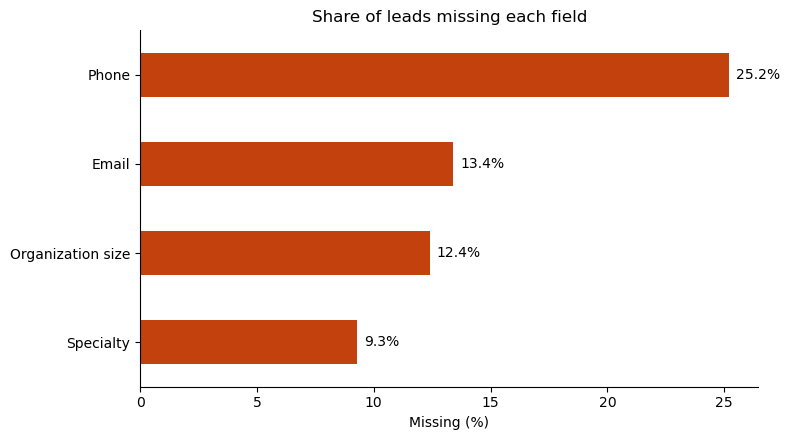

In [3]:
missing = quality[["pct_missing_phone", "pct_missing_email", "pct_missing_specialty", "pct_missing_size"]].T[0]
missing.index = ["Phone", "Email", "Specialty", "Organization size"]
ax = missing.sort_values().plot.barh(color=ORANGE)
ax.set(title="Share of leads missing each field", xlabel="Missing (%)")
for i, v in enumerate(missing.sort_values()):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center")
plt.tight_layout(); plt.savefig("../images/data_quality.png", dpi=150, bbox_inches="tight"); plt.show()

Forty duplicate rows and inconsistent capitalization (for example `HOSPITAL` vs `Hospital`) are fixed in `sql/02_clean_leads.sql`, which keeps one row per lead with `ROW_NUMBER() OVER (PARTITION BY lead_id ...)`.

## 2. The scoring model (`sql/03_score_and_rank.sql`)
| Component | Points | Signals |
|---|---|---|
| Contact completeness | 0-30 | email, phone, decision maker identified |
| Engagement | 0-35 | website visits, email opens (capped), recency of last activity |
| Outreach readiness | 0-35 | research complete, warm source, organization type |

A rules-based score was chosen on purpose: every point can be explained to a sales owner, and the weights are easy to adjust as outcome data accumulates.

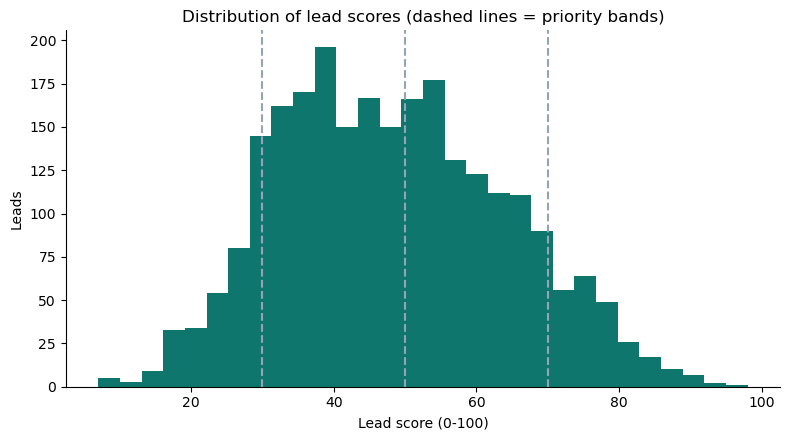

,leads
priority,
Contact this week,261
Nurture,881
Complete research,1080
Deprioritize,278


In [4]:
ax = scored["lead_score"].plot.hist(bins=30, color=TEAL)
for cut in [30, 50, 70]:
    ax.axvline(cut, color=GREY, ls="--")
ax.set(title="Distribution of lead scores (dashed lines = priority bands)", xlabel="Lead score (0-100)", ylabel="Leads")
plt.tight_layout(); plt.savefig("../images/score_distribution.png", dpi=150, bbox_inches="tight"); plt.show()
scored["priority"].value_counts().reindex(["Contact this week", "Nurture", "Complete research", "Deprioritize"]).to_frame("leads")

## 3. Top-50 outreach queue

In [5]:
cols = ["overall_rank", "lead_id", "owner", "org_type", "lead_source", "lead_score",
        "completeness_pts", "engagement_pts", "readiness_pts", "priority"]
scored[cols].head(10)

,overall_rank,lead_id,owner,org_type,lead_source,lead_score,completeness_pts,engagement_pts,readiness_pts,priority
0,1,L101939,Owner B,Pharmaceutical company,Referral,98,30,33,35,Contact this week
1,2,L101886,Owner E,Hospital,Referral,94,30,29,35,Contact this week
2,3,L100433,Owner C,Clinic,Webinar,93,30,33,30,Contact this week
3,4,L102229,Owner C,Clinic,Website form,91,30,31,30,Contact this week
4,5,L100547,Owner B,Hospital,Website form,90,30,25,35,Contact this week
5,5,L100588,Owner D,Hospital,Website form,90,30,25,35,Contact this week
6,7,L100513,Owner C,Hospital,Website form,90,30,25,35,Contact this week
7,8,L100909,Owner C,Hospital,Webinar,90,30,25,35,Contact this week
8,9,L101102,Owner A,Clinic,Website form,89,30,29,30,Contact this week
9,10,L102161,Owner E,Hospital,Website form,89,30,24,35,Contact this week


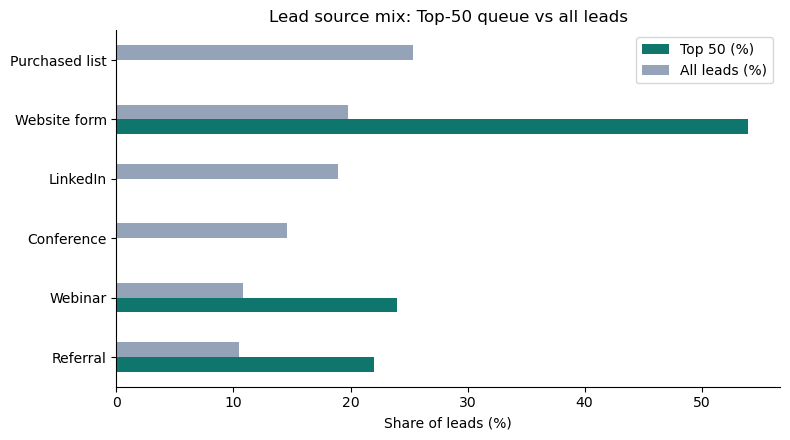

,Top 50 (%),All leads (%)
lead_source,,
Conference,0.0,14.6
LinkedIn,0.0,18.9
Purchased list,0.0,25.3
Referral,22.0,10.5
Webinar,24.0,10.8
Website form,54.0,19.8


In [6]:
top50 = scored[scored["overall_rank"] <= 50]
mix = pd.DataFrame({"Top 50 (%)": top50["lead_source"].value_counts(normalize=True) * 100,
                    "All leads (%)": scored["lead_source"].value_counts(normalize=True) * 100}).fillna(0).round(1)
ax = mix.sort_values("All leads (%)").plot.barh(color=[TEAL, GREY], figsize=(8, 4.5))
ax.set(title="Lead source mix: Top-50 queue vs all leads", xlabel="Share of leads (%)", ylabel="")
plt.tight_layout(); plt.savefig("../images/top50_source_mix.png", dpi=150, bbox_inches="tight"); plt.show()
mix

## 4. A queue for each owner
Ranking within each owner (`RANK() OVER (PARTITION BY owner ...)`) gives every team member their own short list instead of one shared queue.

In [7]:
pd.read_sql('''
    SELECT owner,
           COUNT(*)                                               AS leads,
           ROUND(AVG(lead_score), 1)                              AS avg_score,
           SUM(CASE WHEN lead_score >= 70 THEN 1 ELSE 0 END)      AS contact_this_week,
           SUM(CASE WHEN research_complete = 0 THEN 1 ELSE 0 END) AS research_backlog
    FROM scored_leads
    GROUP BY owner
    ORDER BY contact_this_week DESC
''', con)

,owner,leads,avg_score,contact_this_week,research_backlog
0,Owner E,527,48.0,54,374
1,Owner B,493,49.5,54,334
2,Owner C,490,48.6,53,339
3,Owner A,469,48.7,52,322
4,Owner D,521,47.2,48,363


## 5. KPI scorecard by lead source (`sql/04_kpis.sql`)

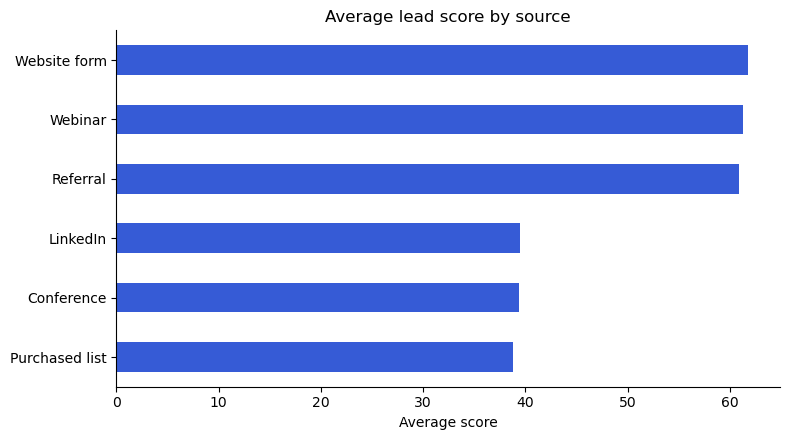

,lead_source,leads,avg_score,in_top_50,pct_contact_ready
0,Website form,496,61.8,27,36.5
1,Webinar,269,61.3,12,35.7
2,Referral,263,60.9,11,31.6
3,LinkedIn,473,39.5,0,16.9
4,Conference,366,39.4,0,19.7
5,Purchased list,633,38.8,0,17.1


In [8]:
ax = kpis.set_index("lead_source")["avg_score"].sort_values().plot.barh(color=BLUE)
ax.set(title="Average lead score by source", xlabel="Average score", ylabel="")
plt.tight_layout(); plt.savefig("../images/score_by_source.png", dpi=150, bbox_inches="tight"); plt.show()
kpis

## 6. Takeaways
- **Clean first, then score.** Duplicates and missing contact fields would otherwise push incomplete leads up the queue.
- **Warm sources fill the Top 50.** Referrals, webinars, and website forms supply every lead in the Top 50, while purchased lists are a quarter of the list and supply none. This is partly by design (source is one input to the score), but warm leads also show more engagement, a signal to rethink list spend.
- **Research is the bottleneck.** About two-thirds of each owner's leads still need research, worth 15 points, so a research sprint would move many leads into the outreach queue.

**Limitations.** The data is synthetic and the weights are set by judgment, not learned. With real conversion outcomes, the next step would be to validate the score (for example, conversion rate by score band) and refit the weights.